# Viability vs. morphology response

For each patient, compares every non-DMSO treatment against that patient's own DMSO baseline on two axes:

- **Morphology**: cosine similarity (`coop::cosine`) between the treatment's full morphology feature vector and the patient's DMSO feature vector.
- **Viability**: signed log2 fold-change vs DMSO (viability has no multi-feature vector to take a real cosine similarity over - a literal 1-D cosine against a single positive percentage would always equal 1.0 and carry no information).

In [1]:
packages <- c("dplyr", "ggplot2", "tidyr", "patchwork", "arrow", "coop", "RColorBrewer")
for (pkg in packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(pkg, character.only = TRUE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

git_root <- find_git_root()
source(file.path(git_root, "utils", "r_plot_themes.r"))
source(file.path(git_root, "utils", "r_plot_funcs.r"))

In [2]:
morphology_profile_path <- file.path(
    git_root, "data", "profiles_3D", "all_patients", "3.consensus_profiles",
    "sc_norm_sc_consensus_profiles.parquet"
)
viability_log2fc_path <- file.path(
    git_root, "5.differential_analysis", "results", "viability_log2fc.parquet"
)
results_dir <- file.path(git_root, "5.differential_analysis", "results")
figures_dir <- file.path(git_root, "5.differential_analysis", "figures")
dir.create(results_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

metadata_cols <- c(
    "Metadata_Biology_PatientTumor", "Metadata_Experiment_Treatment",
    "Metadata_Experiment_Dose", "Metadata_Experiment_Class",
    "Metadata_Experiment_Target", "Metadata_Experiment_TherapeuticCategories",
    "Metadata_Experiment_Unit"
)

morphology_df <- arrow::read_parquet(morphology_profile_path) %>%
    dplyr::filter(!is.na(Metadata_Experiment_Treatment))
feature_cols <- setdiff(colnames(morphology_df), metadata_cols)
head(morphology_df)

Metadata_Biology_PatientTumor,Metadata_Experiment_Treatment,Metadata_Experiment_Dose,Metadata_Experiment_Class,Metadata_Experiment_Target,Metadata_Experiment_TherapeuticCategories,Metadata_Experiment_Unit,Cell_AGP-Mito_Colocalization_Correlation,Cell_AGP-Mito_Colocalization_MandersCoeffCostesM1,Cell_AGP-Mito_Colocalization_MandersCoeffCostesM2,⋯,Nuclei_Mito_Texture_DifferenceVariance-3-01-256,Nuclei_Mito_Texture_InformationMeasureOfCorrelation1-3-00-256,Nuclei_Mito_Texture_InformationMeasureOfCorrelation1-3-12-256,Nuclei_Mito_Texture_InformationMeasureOfCorrelation2-3-00-256,Nuclei_Mito_Texture_InformationMeasureOfCorrelation2-3-06-256,Nuclei_Mito_Texture_SumAverage-3-00-256,Nuclei_Mito_Texture_SumVariance-3-11-256,Nuclei_NoChannel_VolumeSizeShape_BboxVolume,Nuclei_NoChannel_VolumeSizeShape_Extent,Nuclei_NoChannel_VolumeSizeShape_Volume
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
NF0014_T1,Binimetinib,1,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,0.66324460,0.9508419,0.81664787,⋯,-0.02661507,-0.09242495,-0.82346502,0.7350251,1.6656632,0.10540716,0.3888805,-0.22695342,-0.10802882,-0.3224117
NF0014_T1,Binimetinib,10,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,0.67639309,1.1971168,1.08322075,⋯,0.61490657,-1.27912041,-2.98309528,1.8513713,2.8103907,0.25699714,0.7842277,-0.42322673,0.05761095,-0.3660517
NF0014_T1,Cabozantinib,1,Small Molecule,receptor tyrosine kinase inhibitor,Kinase Inhibitor,uM,0.39571227,0.7985266,0.75347181,⋯,-0.07249872,-0.32836585,-0.90959798,1.0755892,1.2772487,-0.29801114,0.4418145,-0.30442604,0.25083594,-0.1051810
NF0014_T1,Copanlisib,1,Small Molecule,PI3K inhibitor,Kinase Inhibitor,uM,0.28212853,0.3900885,0.09067925,⋯,-0.39137039,-0.27491545,-0.08673984,0.6528918,0.7506801,0.04545129,0.1575702,-0.96644571,-0.05728180,-1.2074574
NF0014_T1,DMSO,1,Control,Control,Control,%,0.03990334,0.2377005,0.22482191,⋯,-0.18508332,0.19815212,0.37085059,-0.0771296,-0.2797213,0.17185405,-0.1187105,-0.09740042,0.20111901,-0.0226682
NF0014_T1,Digoxin,1,Small Molecule,Na+/K+ pump inhibitor,Cardiac Glycosides,uM,-0.02204752,0.3503594,0.39458240,⋯,0.15355625,-1.34551537,-2.73755457,1.7177039,2.5149345,-1.22248188,0.5805063,-1.41720189,0.26776482,-1.6148668


## Morphology cosine similarity

Per patient: every treatment's morphology feature vector against that same patient's DMSO feature vector, via `coop::cosine()` (`coop` isn't in this project's pinned R environment by default for `lsa`-style cosine similarity, but is fast and purpose-built for exactly this - a full pairwise cosine matrix per patient, column = sample, row = feature).

In [3]:
compute_patient_cosine <- function(patient_df) {
    #' For one patient: cosine similarity (coop::cosine) of every
    #' treatment's morphology feature vector against that patient's own
    #' DMSO feature vector. Returns one row per non-DMSO treatment.
    dmso_row <- which(patient_df$Metadata_Experiment_Treatment == "DMSO")
    if (length(dmso_row) != 1) {
        warning(
            "expected exactly one DMSO row for ",
            unique(patient_df$Metadata_Biology_PatientTumor),
            ", found ", length(dmso_row), " - skipping patient"
        )
        return(patient_df[0, ])
    }
    # coop::cosine() compares matrix columns pairwise, so each sample
    # (treatment or DMSO) is one column and each feature is one row.
    feature_mat <- t(as.matrix(patient_df[, feature_cols]))
    similarity_to_dmso <- coop::cosine(feature_mat)[, dmso_row]
    patient_df$morphology_cosine_similarity <- similarity_to_dmso
    patient_df[-dmso_row, ]
}

morphology_cosine_df <- morphology_df %>%
    split(.$Metadata_Biology_PatientTumor) %>%
    lapply(compute_patient_cosine) %>%
    dplyr::bind_rows() %>%
    dplyr::select(dplyr::all_of(metadata_cols), morphology_cosine_similarity)
head(morphology_cosine_df)

Metadata_Biology_PatientTumor,Metadata_Experiment_Treatment,Metadata_Experiment_Dose,Metadata_Experiment_Class,Metadata_Experiment_Target,Metadata_Experiment_TherapeuticCategories,Metadata_Experiment_Unit,morphology_cosine_similarity
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
NF0014_T1,Binimetinib,1,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,0.06501983
NF0014_T1,Binimetinib,10,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,-0.10184371
NF0014_T1,Cabozantinib,1,Small Molecule,receptor tyrosine kinase inhibitor,Kinase Inhibitor,uM,0.20950307
NF0014_T1,Copanlisib,1,Small Molecule,PI3K inhibitor,Kinase Inhibitor,uM,0.19608352
NF0014_T1,Digoxin,1,Small Molecule,Na+/K+ pump inhibitor,Cardiac Glycosides,uM,-0.06805627
NF0014_T1,Everolimus,1,Small Molecule,mTOR inhibitor,Kinase Inhibitor,uM,0.45108730


## Join with viability response

Viability measurements only exist for 9 of the 13 morphology-profiled patients (and not every drug/dose was run in both assays), so `viability_log2fc` is `NA` wherever no matching viability measurement exists - this is a left join on purpose, to keep every morphology-profiled treatment in the output.

In [4]:
viability_df <- arrow::read_parquet(viability_log2fc_path) %>%
    dplyr::select(
        Metadata_Biology_PatientTumor, Metadata_Experiment_Treatment, Metadata_Experiment_Dose,
        Metadata_Viability_Percentage, Metadata_DMSO_Viability_Percentage, viability_log2fc
    )

response_df <- morphology_cosine_df %>%
    dplyr::left_join(
        viability_df,
        by = c("Metadata_Biology_PatientTumor", "Metadata_Experiment_Treatment", "Metadata_Experiment_Dose")
    )

## Plot: morphology response vs viability response

Same scatter (morphology cosine similarity vs viability log2FC), recolored by each grouping variable in turn, using this repo's existing palettes (`utils/r_plot_themes.r`): `patient_palette`, `tumor_type_palette`, `custom_treatment_palette`, `custom_MOA_palette`. The 5 treatments with the largest viability drop overall, and the 5 strongest MEK1/2 inhibitor responses, are labeled by name with `ggrepel` on every page.

In [5]:
# tumor_type_lookup/patient_palette (utils/r_plot_themes.r) don't carry
# NF0037_T1_CQ1 - it's the same tumor re-imaged on a different instrument
# (CQ1), so it inherits NF0037_T1's tumor type and color.
local_tumor_type_lookup <- c(tumor_type_lookup, NF0037_T1_CQ1 = tumor_type_lookup[["NF0037_T1"]])
local_patient_palette <- c(patient_palette, NF0037_T1_CQ1 = patient_palette[["NF0037_T1"]])
# custom_MOA_palette's one multi-word key uses an embedded newline for
# compact legend wrapping; Metadata_Experiment_Target stores it as a plain
# space, so match palette names to the data instead of changing the data.
local_moa_palette <- setNames(custom_MOA_palette, gsub("\n", " ", names(custom_MOA_palette)))

response_df <- response_df %>%
    dplyr::mutate(
        Metadata_Biology_TumorType = local_tumor_type_lookup[Metadata_Biology_PatientTumor],
        Metadata_Biology_PatientTumor = factor(
            Metadata_Biology_PatientTumor, levels = names(local_patient_palette)
        ),
        Metadata_Biology_TumorType = factor(
            Metadata_Biology_TumorType, levels = names(tumor_type_palette)
        ),
        Metadata_Experiment_Treatment = factor(
            Metadata_Experiment_Treatment, levels = names(custom_treatment_palette)
        ),
        Metadata_Experiment_Target = factor(
            Metadata_Experiment_Target, levels = names(local_moa_palette)
        )
    )

arrow::write_parquet(
    response_df, file.path(results_dir, "morphology_viability_cosine_similarity.parquet")
)
response_df

Metadata_Biology_PatientTumor,Metadata_Experiment_Treatment,Metadata_Experiment_Dose,Metadata_Experiment_Class,Metadata_Experiment_Target,Metadata_Experiment_TherapeuticCategories,Metadata_Experiment_Unit,morphology_cosine_similarity,Metadata_Viability_Percentage,Metadata_DMSO_Viability_Percentage,viability_log2fc,Metadata_Biology_TumorType
<fct>,<fct>,<dbl>,<chr>,<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
NF0014_T1,Binimetinib,1,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,0.065019835,95.746646,100,-0.06270615,cNF
NF0014_T1,Binimetinib,10,Small Molecule,MEK1/2 inhibitor,Kinase Inhibitor,uM,-0.101843714,87.146456,100,-0.19848609,cNF
NF0014_T1,Cabozantinib,1,Small Molecule,receptor tyrosine kinase inhibitor,Kinase Inhibitor,uM,0.209503066,118.802084,100,0.24856014,cNF
NF0014_T1,Copanlisib,1,Small Molecule,PI3K inhibitor,Kinase Inhibitor,uM,0.196083517,45.043833,100,-1.15059849,cNF
NF0014_T1,Digoxin,1,Small Molecule,Na+/K+ pump inhibitor,Cardiac Glycosides,uM,-0.068056272,22.499116,100,-2.15205974,cNF
NF0014_T1,Everolimus,1,Small Molecule,mTOR inhibitor,Kinase Inhibitor,uM,0.451087297,79.889192,100,-0.32392776,cNF
NF0014_T1,Fimepinostat,1,Small Molecule,PI3K and HDAC inhibitor,Investigational,uM,0.062247417,39.494294,100,-1.34028385,cNF
NF0014_T1,Imatinib,1,Small Molecule,tyrosine kinase inhibitor,Kinase Inhibitor,uM,0.584962912,114.157708,100,0.19102828,cNF
NF0014_T1,Ketotifen,1,Small Molecule,histamine H1 receptor antagonist,Anti-Allergic Agents,uM,0.188438052,112.776023,100,0.17346038,cNF


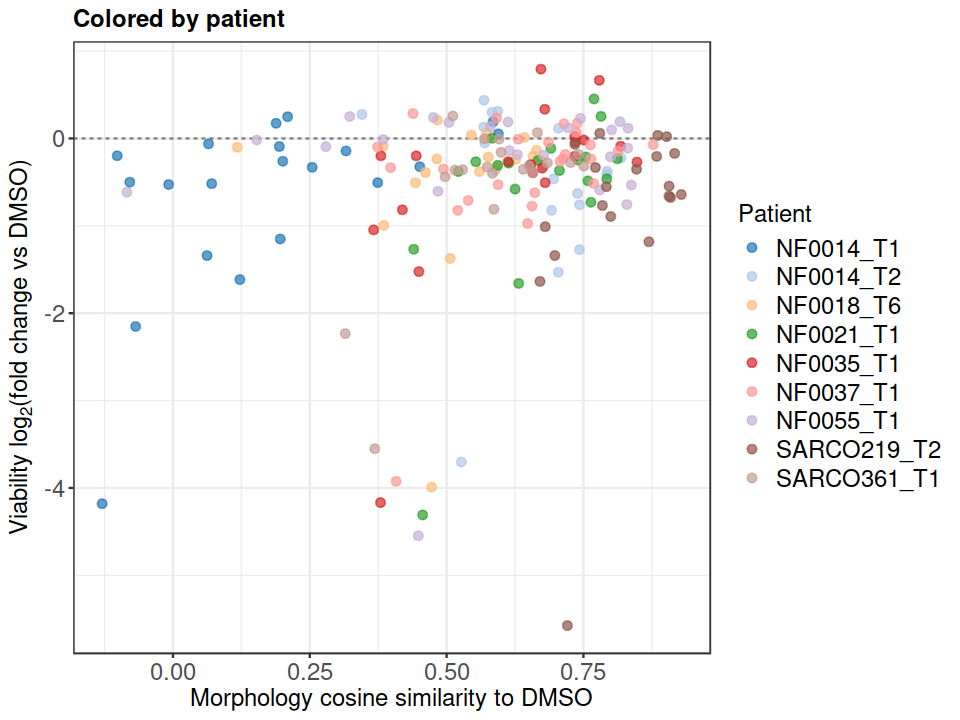

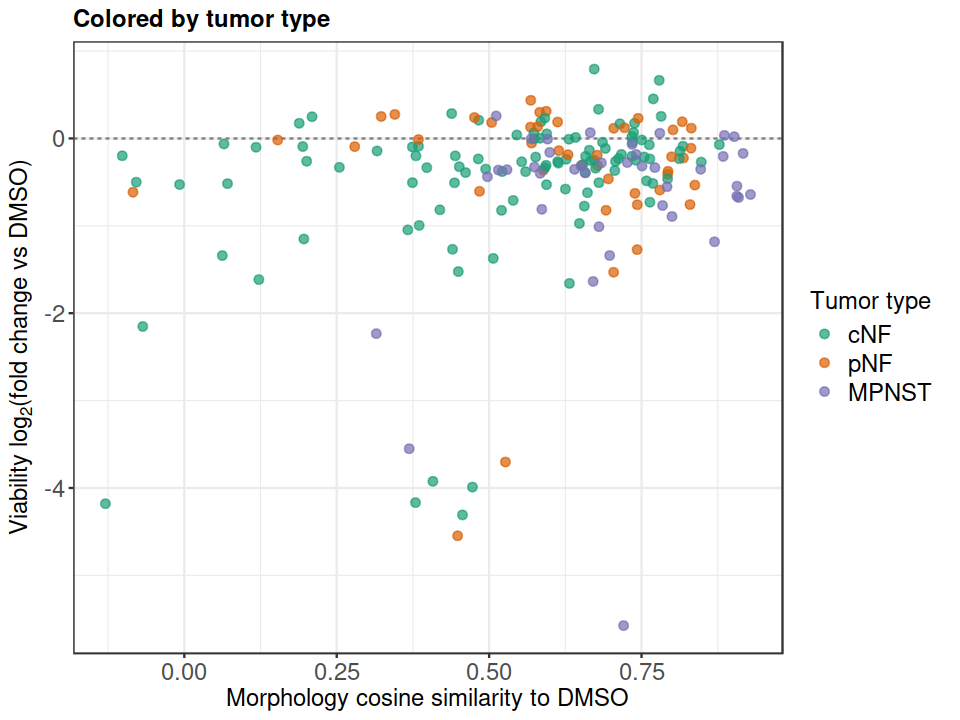

[[1]]

[[2]]

[[3]]

[[4]]


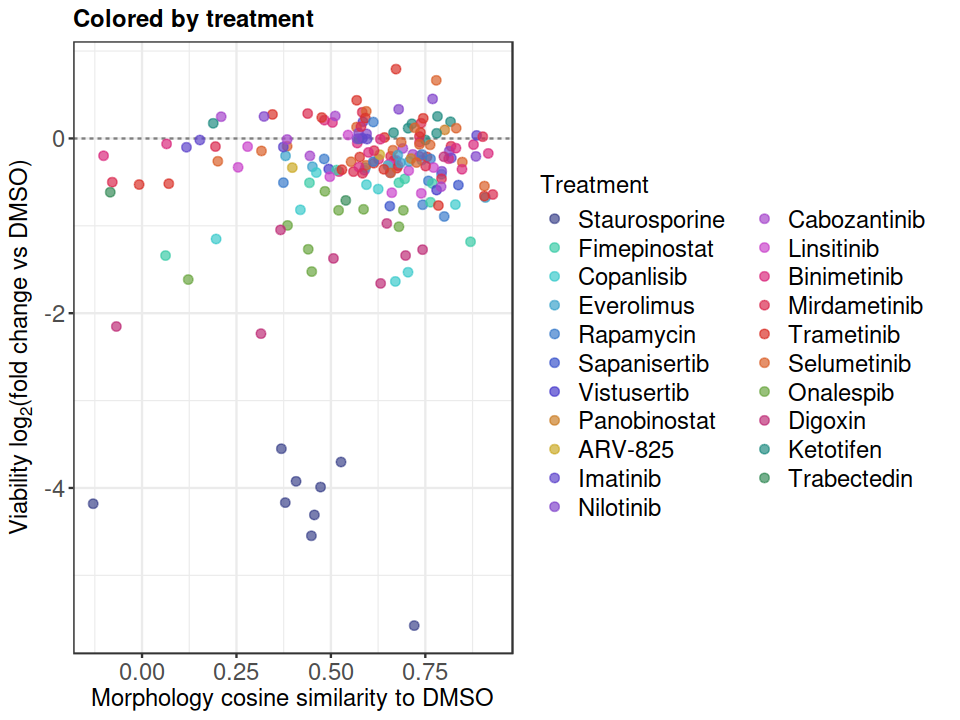

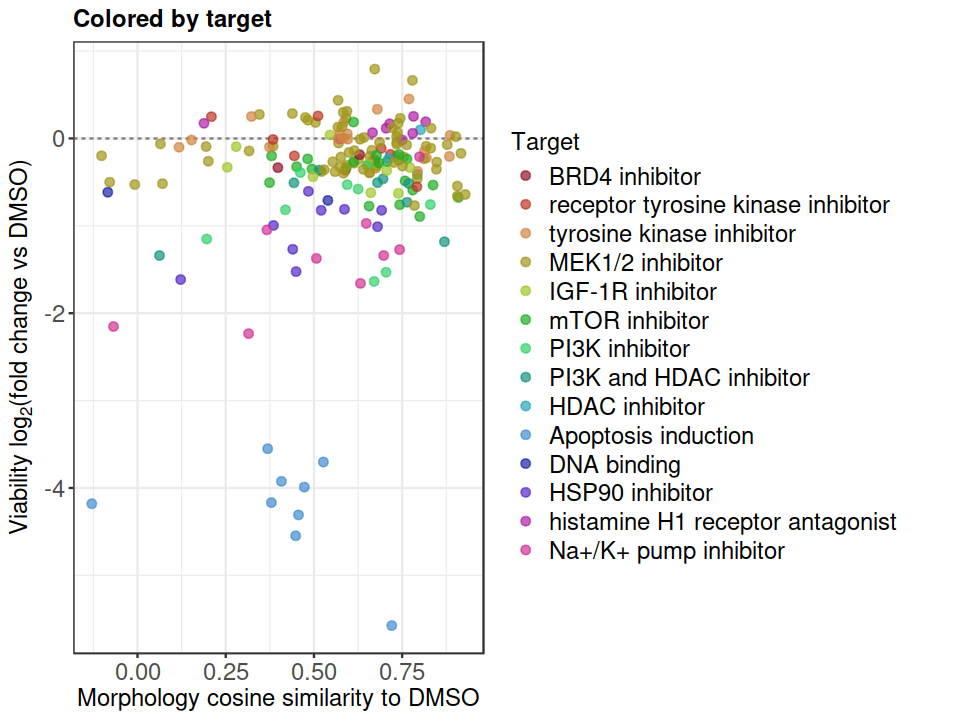

In [6]:
width <- 8
height <- 6
dims <- set_plot_size(width, height)

plot_morphology_vs_viability <- function(color_by, palette, legend_title, plot_title) {
    #' Same morphology-cosine-similarity-vs-viability-log2FC scatter,
    #' recolored by a different grouping variable each call.
    plot_data <- response_df %>% dplyr::filter(!is.na(viability_log2fc))
    (
        ggplot(
            plot_data,
            aes(x = morphology_cosine_similarity, y = viability_log2fc, color = .data[[color_by]])
        )
        + geom_hline(yintercept = 0, linetype = "dashed", color = "grey50")
        + geom_point(alpha = 0.7, size = 2)
        + scale_color_manual(values = palette, name = legend_title, drop = TRUE, na.translate = FALSE)
        + labs(
            x = "Morphology cosine similarity to DMSO",
            y = expression(paste("Viability ", log[2], "(fold change vs DMSO)")),
            title = plot_title
        )
        + theme_manuscript(base_size = 14)
    )
}

morphology_vs_viability_plots <- list(
    plot_morphology_vs_viability(
        "Metadata_Biology_PatientTumor", local_patient_palette, "Patient", "Colored by patient"
    ),
    plot_morphology_vs_viability(
        "Metadata_Biology_TumorType", tumor_type_palette, "Tumor type", "Colored by tumor type"
    ),
    plot_morphology_vs_viability(
        "Metadata_Experiment_Treatment", custom_treatment_palette, "Treatment", "Colored by treatment"
    ),
    plot_morphology_vs_viability(
        "Metadata_Experiment_Target", local_moa_palette, "Target", "Colored by target"
    )
)

save_plots_pdf(
    morphology_vs_viability_plots,
    file.path(figures_dir, "morphology_vs_viability_cosine_similarity.pdf"),
    width = dims$width, height = dims$height
)
morphology_vs_viability_plots